# LightGBM Model with Proximity-Based Features
This notebook builds a LightGBM model for predicting monthly rent with enhanced proximity-based features (schools, MRT stations, shopping malls) using a decaying distance factor.

In [2]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from math import radians, sin, cos, sqrt, atan2
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load data
print("Loading data...")
train_df = pd.read_csv('../data/train.csv')
test_df = pd.read_csv('../data/test.csv')
hdb_df = pd.read_csv('../data/auxiliary/sg-hdb-block.csv')
schools_df = pd.read_csv('../data/auxiliary/sg-schools.csv')
mrt_df = pd.read_csv('../data/auxiliary/sg-mrt-stations.csv')
malls_df = pd.read_csv('../data/auxiliary/sg-shopping-malls.csv')

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"HDB blocks shape: {hdb_df.shape}")
print(f"Schools shape: {schools_df.shape}")
print(f"MRT stations shape: {mrt_df.shape}")
print(f"Shopping malls shape: {malls_df.shape}")

Loading data...
Train shape: (150000, 11)
Test shape: (50000, 10)
HDB blocks shape: (9464, 11)
Schools shape: (337, 14)
MRT stations shape: (243, 8)
Shopping malls shape: (113, 3)


In [4]:
# Available Features from All Datasets
print("=" * 80)
print("AVAILABLE FEATURES FROM ALL DATASETS")
print("=" * 80)

print("\n1. TRAIN/TEST DATA (Rental Information):")
print(f"   Columns: {train_df.columns.tolist()}")
print(f"   Target: MONTHLY_RENT (train data only)")

print("\n2. HDB BLOCK DATA (Residential Block Information):")
print(f"   Columns: {hdb_df.columns.tolist()}")

print("\n3. SCHOOLS DATA (Educational Institutions):")
print(f"   Columns: {schools_df.columns.tolist()}")
print(f"   Sample types: {schools_df['TYPE_CODE'].unique()[:5].tolist()}")
print(f"   Total schools: {len(schools_df)}")

print("\n4. MRT STATIONS DATA (Public Transport):")
print(f"   Columns: {mrt_df.columns.tolist()}")
print(f"   Sample statuses: {mrt_df['STATUS'].unique().tolist()}")
print(f"   Total stations: {len(mrt_df)}")

print("\n5. SHOPPING MALLS DATA (Commercial Facilities):")
print(f"   Columns: {malls_df.columns.tolist()}")
print(f"   Total malls: {len(malls_df)}")

print("\n" + "=" * 80)
print("FEATURE ENGINEERING OPPORTUNITY:")
print("=" * 80)
print("""
Potential features to create from these datasets:
- From HDB data: MAX_FLOOR, YEAR_COMPLETED, SUBZONE, PLANNING_AREA, REGION
- From Schools data: Type of school, number of schools in proximity with weights
- From MRT data: Number of MRT stations, distance to nearest MRT
- From Malls data: Number of shopping malls, distance to nearest mall
- Proximity scoring: Using decaying distance factors for nearby facilities
- Temporal features: Years since lease commencement, approval date patterns
- Location features: Planning area, region, and subzone encoding
""")

AVAILABLE FEATURES FROM ALL DATASETS

1. TRAIN/TEST DATA (Rental Information):
   Columns: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT']
   Target: MONTHLY_RENT (train data only)

2. HDB BLOCK DATA (Residential Block Information):
   Columns: ['TOWN', 'BLOCK', 'STREET', 'POSTAL_CODE', 'LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'YEAR_COMPLETED', 'SUBZONE', 'PLANNING_AREA', 'REGION']

3. SCHOOLS DATA (Educational Institutions):
   Columns: ['NAME', 'URL', 'STREET', 'POSTAL_CODE', 'MRT_STATIONS', 'BUS_LINES', 'PLANNING_AREA', 'REGION', 'TYPE_CODE', 'NATRUE_CODE', 'SESSION_CODE', 'MAINLEVEL_CODE', 'LATITUDE', 'LONGITUDE']
   Sample types: ['government school', 'government-aided sch', 'independent school', 'specialised independent school', 'specialised school']
   Total schools: 337

4. MRT STATIONS DATA (Public Transport):
   Columns: ['CODE', 'NAME', 'STATUS', 'LATITUDE', 'LONGITUDE', 'S

In [5]:
# Haversine formula to calculate distance between two coordinates (in km)
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the great circle distance between two points 
    on the earth (specified in decimal degrees)
    Returns distance in kilometers
    """
    # Convert to radians
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    
    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    r = 6371  # Radius of earth in kilometers
    return c * r

# Decaying factor function
def compute_proximity_score(hdb_lat, hdb_lon, facility_lats, facility_lons):
    """
    Compute proximity score using decaying factor:
    within_0.5km^1 + within_1km^0.8 + within_2km^0.5 + within_5km^0.2
    """
    score = 0
    
    for fac_lat, fac_lon in zip(facility_lats, facility_lons):
        dist = haversine_distance(hdb_lat, hdb_lon, fac_lat, fac_lon)
        
        if dist <= 0.5:
            score += 1.0
        elif dist <= 1.0:
            score += 0.8
        elif dist <= 2.0:
            score += 0.5
        elif dist <= 5.0:
            score += 0.2
    
    return score

print("Distance and proximity functions defined!")

Distance and proximity functions defined!


In [6]:
# Distance band counting function - counts buildings in each distance band
def compute_proximity_bands(hdb_lat, hdb_lon, facility_lats, facility_lons):
    """
    Count facilities within specific distance bands
    Returns a dictionary with counts for each distance band:
    - within_0_5km: facilities within 0.5 km
    - within_1km: facilities within 1 km
    - within_2km: facilities within 2 km
    - within_5km: facilities within 5 km
    """
    within_0_5 = 0
    within_1 = 0
    within_2 = 0
    within_5 = 0
    
    for fac_lat, fac_lon in zip(facility_lats, facility_lons):
        dist = haversine_distance(hdb_lat, hdb_lon, fac_lat, fac_lon)
        
        if dist <= 0.5:
            within_0_5 += 1
            within_1 += 1
            within_2 += 1
            within_5 += 1
        elif dist <= 1.0:
            within_1 += 1
            within_2 += 1
            within_5 += 1
        elif dist <= 2.0:
            within_2 += 1
            within_5 += 1
        elif dist <= 5.0:
            within_5 += 1
    
    return {
        'within_0_5km': within_0_5,
        'within_1km': within_1,
        'within_2km': within_2,
        'within_5km': within_5
    }

print("Distance band function defined!")

Distance band function defined!


In [7]:
# Merge train data with HDB coordinates
from sklearn.impute import KNNImputer

train_with_coords = train_df.copy()
test_with_coords = test_df.copy()

# Merge with HDB data to get coordinates
train_with_coords = train_with_coords.merge(
    hdb_df[['BLOCK', 'STREET', 'LATITUDE', 'LONGITUDE']],
    left_on=['BLOCK', 'STREET'],
    right_on=['BLOCK', 'STREET'],
    how='left'
)

test_with_coords = test_with_coords.merge(
    hdb_df[['BLOCK', 'STREET', 'LATITUDE', 'LONGITUDE']],
    left_on=['BLOCK', 'STREET'],
    right_on=['BLOCK', 'STREET'],
    how='left'
)

print(f"Train shape after merge: {train_with_coords.shape}")
print(f"Train missing coordinates: {train_with_coords['LATITUDE'].isna().sum()}")
print(f"Test missing coordinates: {test_with_coords['LATITUDE'].isna().sum()}")

# KNN Imputation based on address similarity
def impute_coordinates_knn(df):
    """
    Impute missing coordinates using KNN based on TOWN and STREET similarity
    """
    df_impute = df.copy()
    
    # Encode categorical features
    town_encoder = pd.factorize(df_impute['TOWN'])[0]
    street_encoder = pd.factorize(df_impute['STREET'])[0]
    
    # Create feature matrix for KNN: [town_encoded, street_encoded, latitude, longitude]
    impute_matrix = np.column_stack([town_encoder, street_encoder, 
                                     df_impute['LATITUDE'].values, 
                                     df_impute['LONGITUDE'].values])
    
    # Apply KNN imputation (k=5 nearest neighbors)
    imputer = KNNImputer(n_neighbors=5, weights='distance')
    imputed_matrix = imputer.fit_transform(impute_matrix)
    
    # Extract imputed coordinates
    df_impute['LATITUDE'] = imputed_matrix[:, 2]
    df_impute['LONGITUDE'] = imputed_matrix[:, 3]
    
    return df_impute

# Apply KNN imputation
train_with_coords = impute_coordinates_knn(train_with_coords)
test_with_coords = impute_coordinates_knn(test_with_coords)

print("\nKNN Imputation completed!")
print(f"Train missing coordinates after imputation: {train_with_coords['LATITUDE'].isna().sum()}")
print(f"Test missing coordinates after imputation: {test_with_coords['LATITUDE'].isna().sum()}")
print(f"\nCoordinates imputed based on address similarity using KNN (k=5)")

Train shape after merge: (150000, 13)
Train missing coordinates: 30781
Test missing coordinates: 10482

KNN Imputation completed!
Train missing coordinates after imputation: 0
Test missing coordinates after imputation: 0

Coordinates imputed based on address similarity using KNN (k=5)


In [8]:
# Create proximity features
print("Computing proximity features for schools...")
train_with_coords['schools_nearby'] = train_with_coords.apply(
    lambda row: compute_proximity_score(
        row['LATITUDE'], row['LONGITUDE'],
        schools_df['LATITUDE'].values, schools_df['LONGITUDE'].values
    ), axis=1
)

test_with_coords['schools_nearby'] = test_with_coords.apply(
    lambda row: compute_proximity_score(
        row['LATITUDE'], row['LONGITUDE'],
        schools_df['LATITUDE'].values, schools_df['LONGITUDE'].values
    ), axis=1
)

print("Computing proximity features for MRT stations...")
train_with_coords['mrt_nearby'] = train_with_coords.apply(
    lambda row: compute_proximity_score(
        row['LATITUDE'], row['LONGITUDE'],
        mrt_df['LATITUDE'].values, mrt_df['LONGITUDE'].values
    ), axis=1
)

test_with_coords['mrt_nearby'] = test_with_coords.apply(
    lambda row: compute_proximity_score(
        row['LATITUDE'], row['LONGITUDE'],
        mrt_df['LATITUDE'].values, mrt_df['LONGITUDE'].values
    ), axis=1
)

print("Computing proximity features for shopping malls...")
train_with_coords['shoppingmalls_nearby'] = train_with_coords.apply(
    lambda row: compute_proximity_score(
        row['LATITUDE'], row['LONGITUDE'],
        malls_df['LATITUDE'].values, malls_df['LONGITUDE'].values
    ), axis=1
)

test_with_coords['shoppingmalls_nearby'] = test_with_coords.apply(
    lambda row: compute_proximity_score(
        row['LATITUDE'], row['LONGITUDE'],
        malls_df['LATITUDE'].values, malls_df['LONGITUDE'].values
    ), axis=1
)

print("\nProximity features computed!")
print(f"Schools nearby stats:\n{train_with_coords['schools_nearby'].describe()}")
print(f"\nMRT nearby stats:\n{train_with_coords['mrt_nearby'].describe()}")
print(f"\nShopping malls nearby stats:\n{train_with_coords['shoppingmalls_nearby'].describe()}")

Computing proximity features for schools...
Computing proximity features for MRT stations...
Computing proximity features for shopping malls...

Proximity features computed!
Schools nearby stats:
count    150000.000000
mean         16.671468
std           4.539855
min           2.400000
25%          13.200000
50%          16.400000
75%          20.100000
max          27.800000
Name: schools_nearby, dtype: float64

MRT nearby stats:
count    150000.00000
mean          9.87933
std           5.32306
min           1.10000
25%           6.40000
50%           8.70000
75%          11.60000
max          31.30000
Name: mrt_nearby, dtype: float64

Shopping malls nearby stats:
count    150000.000000
mean          5.028969
std           3.412399
min           0.200000
25%           2.900000
50%           4.300000
75%           5.800000
max          21.800000
Name: shoppingmalls_nearby, dtype: float64


In [9]:
# Create distance band features (separate features for each distance band)
print("\n" + "="*60)
print("Computing distance band features...")
print("="*60)

# Schools - distance bands
print("\nCreating school distance band features...")
schools_bands_train = train_with_coords.apply(
    lambda row: pd.Series(compute_proximity_bands(
        row['LATITUDE'], row['LONGITUDE'],
        schools_df['LATITUDE'].values, schools_df['LONGITUDE'].values
    )), axis=1
)
schools_bands_train.columns = ['schools_within_0_5km', 'schools_within_1km', 'schools_within_2km', 'schools_within_5km']

schools_bands_test = test_with_coords.apply(
    lambda row: pd.Series(compute_proximity_bands(
        row['LATITUDE'], row['LONGITUDE'],
        schools_df['LATITUDE'].values, schools_df['LONGITUDE'].values
    )), axis=1
)
schools_bands_test.columns = ['schools_within_0_5km', 'schools_within_1km', 'schools_within_2km', 'schools_within_5km']

train_with_coords = pd.concat([train_with_coords, schools_bands_train], axis=1)
test_with_coords = pd.concat([test_with_coords, schools_bands_test], axis=1)

# MRT - distance bands
print("Creating MRT distance band features...")
mrt_bands_train = train_with_coords.apply(
    lambda row: pd.Series(compute_proximity_bands(
        row['LATITUDE'], row['LONGITUDE'],
        mrt_df['LATITUDE'].values, mrt_df['LONGITUDE'].values
    )), axis=1
)
mrt_bands_train.columns = ['mrt_within_0_5km', 'mrt_within_1km', 'mrt_within_2km', 'mrt_within_5km']

mrt_bands_test = test_with_coords.apply(
    lambda row: pd.Series(compute_proximity_bands(
        row['LATITUDE'], row['LONGITUDE'],
        mrt_df['LATITUDE'].values, mrt_df['LONGITUDE'].values
    )), axis=1
)
mrt_bands_test.columns = ['mrt_within_0_5km', 'mrt_within_1km', 'mrt_within_2km', 'mrt_within_5km']

train_with_coords = pd.concat([train_with_coords, mrt_bands_train], axis=1)
test_with_coords = pd.concat([test_with_coords, mrt_bands_test], axis=1)

# Shopping Malls - distance bands
print("Creating shopping mall distance band features...")
malls_bands_train = train_with_coords.apply(
    lambda row: pd.Series(compute_proximity_bands(
        row['LATITUDE'], row['LONGITUDE'],
        malls_df['LATITUDE'].values, malls_df['LONGITUDE'].values
    )), axis=1
)
malls_bands_train.columns = ['malls_within_0_5km', 'malls_within_1km', 'malls_within_2km', 'malls_within_5km']

malls_bands_test = test_with_coords.apply(
    lambda row: pd.Series(compute_proximity_bands(
        row['LATITUDE'], row['LONGITUDE'],
        malls_df['LATITUDE'].values, malls_df['LONGITUDE'].values
    )), axis=1
)
malls_bands_test.columns = ['malls_within_0_5km', 'malls_within_1km', 'malls_within_2km', 'malls_within_5km']

train_with_coords = pd.concat([train_with_coords, malls_bands_train], axis=1)
test_with_coords = pd.concat([test_with_coords, malls_bands_test], axis=1)

print("\n" + "="*60)
print("Distance band features summary:")
print("="*60)
print("\nSchools distance bands:")
print(schools_bands_train.describe())
print("\nMRT distance bands:")
print(mrt_bands_train.describe())
print("\nShopping Malls distance bands:")
print(malls_bands_train.describe())


Computing distance band features...

Creating school distance band features...
Creating MRT distance band features...
Creating shopping mall distance band features...

Distance band features summary:

Schools distance bands:
       schools_within_0_5km  schools_within_1km  schools_within_2km  \
count         150000.000000       150000.000000       150000.000000   
mean               1.658060            5.160833           14.893540   
std                1.184511            2.497827            5.436487   
min                0.000000            0.000000            0.000000   
25%                1.000000            3.000000           11.000000   
50%                2.000000            5.000000           14.000000   
75%                2.000000            7.000000           18.000000   
max                6.000000           15.000000           31.000000   

       schools_within_5km  
count       150000.000000  
mean            51.617720  
std             16.488679  
min             12.000

In [10]:
# Feature engineering function
def feature_engineering(df, is_test=False):
    df = df.copy()
    
    # Parse RENT_APPROVAL_DATE to extract year and month
    df['approval_year'] = df['RENT_APPROVAL_DATE'].str.split('-').str[0].astype(int)
    df['approval_month'] = df['RENT_APPROVAL_DATE'].str.split('-').str[1].astype(int)
    df['approval_date_numeric'] = df['approval_year'] * 12 + df['approval_month']
    
    # Create lease age feature (years since lease commenced)
    df['lease_age'] = df['approval_year'] - df['LEASE_COMMENCE_DATE'].astype(int)
    
    # Handle categorical variables with label encoding
    categorical_cols = ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL', 'FURNISHED', 'STREET']
    
    for col in categorical_cols:
        df[col + '_encoded'] = pd.factorize(df[col])[0]
    
    # Select features for modeling
    # Includes: temporal features + decaying factor proximity + distance band features
    feature_cols = [
        # Temporal features
        'approval_year', 'approval_month', 'approval_date_numeric',
        'lease_age', 'FLOOR_AREA_SQM', 'FEE',
        
        # Decaying factor proximity features (original)
        'schools_nearby', 'mrt_nearby', 'shoppingmalls_nearby',
        
        # Distance band features for schools
        'schools_within_0_5km', 'schools_within_1km', 'schools_within_2km', 'schools_within_5km',
        
        # Distance band features for MRT
        'mrt_within_0_5km', 'mrt_within_1km', 'mrt_within_2km', 'mrt_within_5km',
        
        # Distance band features for shopping malls
        'malls_within_0_5km', 'malls_within_1km', 'malls_within_2km', 'malls_within_5km',
        
        # Categorical features
        'TOWN_encoded', 'FLAT_TYPE_encoded', 'FLAT_MODEL_encoded', 
        'FURNISHED_encoded', 'STREET_encoded'
    ]
    
    return df, feature_cols

# Apply feature engineering
train_processed, feature_cols = feature_engineering(train_with_coords)
test_processed, _ = feature_engineering(test_with_coords, is_test=True)

print(f"Total features used: {len(feature_cols)}")
print(f"\nFeatures by category:")
print(f"  Temporal: 5 features")
print(f"  Decaying factor proximity: 3 features")
print(f"  Distance band features: 12 features (4 distance bands × 3 facility types)")
print(f"  Categorical encoded: 5 features")
print(f"\nAll features: {feature_cols}")
print(f"\nTraining set shape: {train_processed.shape}")

Total features used: 26

Features by category:
  Temporal: 5 features
  Decaying factor proximity: 3 features
  Distance band features: 12 features (4 distance bands × 3 facility types)
  Categorical encoded: 5 features

All features: ['approval_year', 'approval_month', 'approval_date_numeric', 'lease_age', 'FLOOR_AREA_SQM', 'FEE', 'schools_nearby', 'mrt_nearby', 'shoppingmalls_nearby', 'schools_within_0_5km', 'schools_within_1km', 'schools_within_2km', 'schools_within_5km', 'mrt_within_0_5km', 'mrt_within_1km', 'mrt_within_2km', 'mrt_within_5km', 'malls_within_0_5km', 'malls_within_1km', 'malls_within_2km', 'malls_within_5km', 'TOWN_encoded', 'FLAT_TYPE_encoded', 'FLAT_MODEL_encoded', 'FURNISHED_encoded', 'STREET_encoded']

Training set shape: (150000, 37)


In [11]:
# Prepare training data
X_train = train_processed[feature_cols]
y_train = train_processed['MONTHLY_RENT']

print(f"Features shape: {X_train.shape}")
print(f"Target variable shape: {y_train.shape}")
print(f"\nTarget variable stats:")
print(y_train.describe())

# Check for missing values
print(f"\nMissing values in features:")
print(X_train.isna().sum())

Features shape: (150000, 26)
Target variable shape: (150000,)

Target variable stats:
count    150000.000000
mean       2719.036893
std         749.731096
min         300.000000
25%        2100.000000
50%        2700.000000
75%        3200.000000
max        7600.000000
Name: MONTHLY_RENT, dtype: float64

Missing values in features:
approval_year            0
approval_month           0
approval_date_numeric    0
lease_age                0
FLOOR_AREA_SQM           0
FEE                      0
schools_nearby           0
mrt_nearby               0
shoppingmalls_nearby     0
schools_within_0_5km     0
schools_within_1km       0
schools_within_2km       0
schools_within_5km       0
mrt_within_0_5km         0
mrt_within_1km           0
mrt_within_2km           0
mrt_within_5km           0
malls_within_0_5km       0
malls_within_1km         0
malls_within_2km         0
malls_within_5km         0
TOWN_encoded             0
FLAT_TYPE_encoded        0
FLAT_MODEL_encoded       0
FURNISHED_encoded 

In [12]:
# Split for validation
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

print(f"Train split shape: {X_train_split.shape}")
print(f"Validation split shape: {X_val.shape}")

Train split shape: (120000, 26)
Validation split shape: (30000, 26)


In [13]:
# Train LightGBM model
print("Training LightGBM model...")
model = lgb.LGBMRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=7,
    num_leaves=31,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

model.fit(
    # X_train_split, y_train_split,
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(20)]
)

print("Model training completed!")

Training LightGBM model...
Training until validation scores don't improve for 20 rounds
Did not meet early stopping. Best iteration is:
[200]	valid_0's l2: 222109
Model training completed!


In [ ]:
# Hyperparameter Tuning with Optuna
import optuna
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler

print("Starting Optuna Hyperparameter Tuning...")

def objective(trial):
    """
    Objective function for Optuna to optimize LightGBM hyperparameters
    """
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 1000, step=5),
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'num_leaves': trial.suggest_int('num_leaves', 15, 1000),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1
    }
    
    model_trial = lgb.LGBMRegressor(**params)
    
    model_trial.fit(
        X_train_split, y_train_split,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(10)]
    )
    
    y_pred = model_trial.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    return rmse

# Create study with TPE sampler and median pruner
sampler = TPESampler(seed=42)
pruner = MedianPruner()
study = optuna.create_study(sampler=sampler, pruner=pruner, direction='minimize')

# Optimize
print("Running optimization trials (this may take a few minutes)...")
study.optimize(objective, n_trials=50, show_progress_bar=True)

# Get best parameters
best_params = study.best_params
best_rmse = study.best_value

print(f"\n{'='*60}")
print("OPTUNA OPTIMIZATION RESULTS")
print(f"{'='*60}")
print(f"Best RMSE: {best_rmse:.2f}")
print(f"\nBest Hyperparameters:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

# Train final model with best parameters
print(f"\n{'='*60}")
print("Training final model with best hyperparameters...")
print(f"{'='*60}")

model_optimized = lgb.LGBMRegressor(
    **best_params,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

model_optimized.fit(
    X_train_split, y_train_split,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(20)]
)

# Replace the original model with optimized one
model = model_optimized

print("Optimized model trained and set as primary model!")

In [14]:
# Evaluate on validation set
y_pred_val = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
mae = mean_absolute_error(y_val, y_pred_val)
r2 = r2_score(y_val, y_pred_val)

# Calculate WMAPE (Weighted Mean Absolute Percentage Error)
wmape = (np.sum(np.abs(y_val - y_pred_val)) / np.sum(np.abs(y_val))) * 100

print(f"Validation Metrics:")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R² Score: {r2:.4f}")
print(f"WMAPE: {wmape:.2f}%")

Validation Metrics:
RMSE: 471.28
MAE: 355.89
R² Score: 0.6053
WMAPE: 13.06%


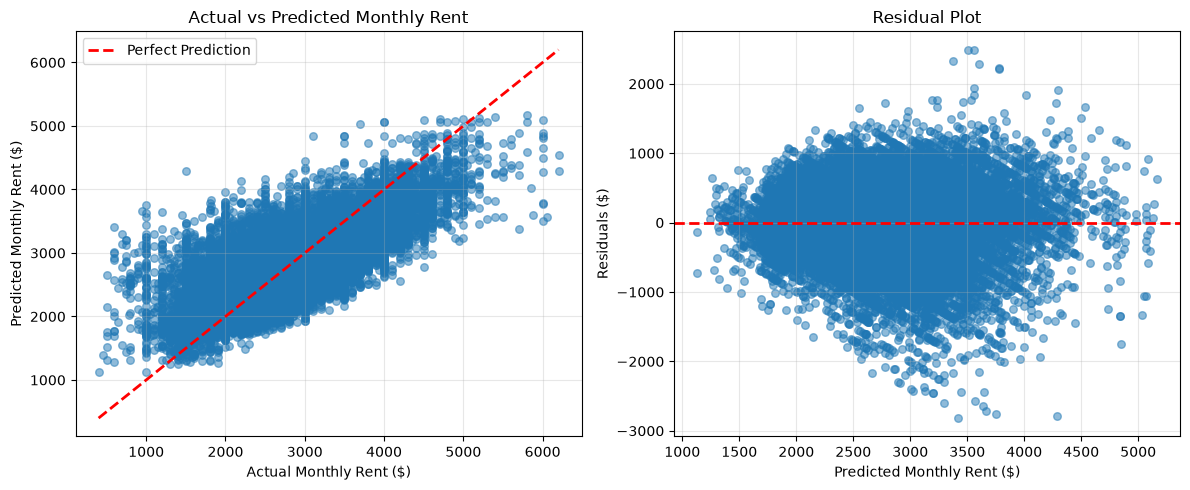


Residual Statistics:
Mean Residual: 2.71
Std Residual: 471.28
Min Residual: -2816.59
Max Residual: 2490.96


In [15]:
import matplotlib.pyplot as plt
# Visualize predicted vs actual values
plt.figure(figsize=(12, 5))

# Scatter plot
plt.subplot(1, 2, 1)
plt.scatter(y_val, y_pred_val, alpha=0.5, s=30)
# Add perfect prediction line
min_val = min(y_val.min(), y_pred_val.min())
max_val = max(y_val.max(), y_pred_val.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Rent ($)')
plt.ylabel('Predicted Monthly Rent ($)')
plt.title('Actual vs Predicted Monthly Rent')
plt.legend()
plt.grid(True, alpha=0.3)

# Residual plot
plt.subplot(1, 2, 2)
residuals = y_val - y_pred_val
plt.scatter(y_pred_val, residuals, alpha=0.5, s=30)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Monthly Rent ($)')
plt.ylabel('Residuals ($)')
plt.title('Residual Plot')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nResidual Statistics:")
print(f"Mean Residual: {residuals.mean():.2f}")
print(f"Std Residual: {residuals.std():.2f}")
print(f"Min Residual: {residuals.min():.2f}")
print(f"Max Residual: {residuals.max():.2f}")

Top 15 Important Features:
                  feature  importance
4          FLOOR_AREA_SQM         780
21           TOWN_encoded         724
3               lease_age         587
2   approval_date_numeric         431
7              mrt_nearby         403
25         STREET_encoded         395
6          schools_nearby         345
12     schools_within_5km         255
16         mrt_within_5km         242
23     FLAT_MODEL_encoded         239
8    shoppingmalls_nearby         239
1          approval_month         205
11     schools_within_2km         165
20       malls_within_5km         136
22      FLAT_TYPE_encoded         126


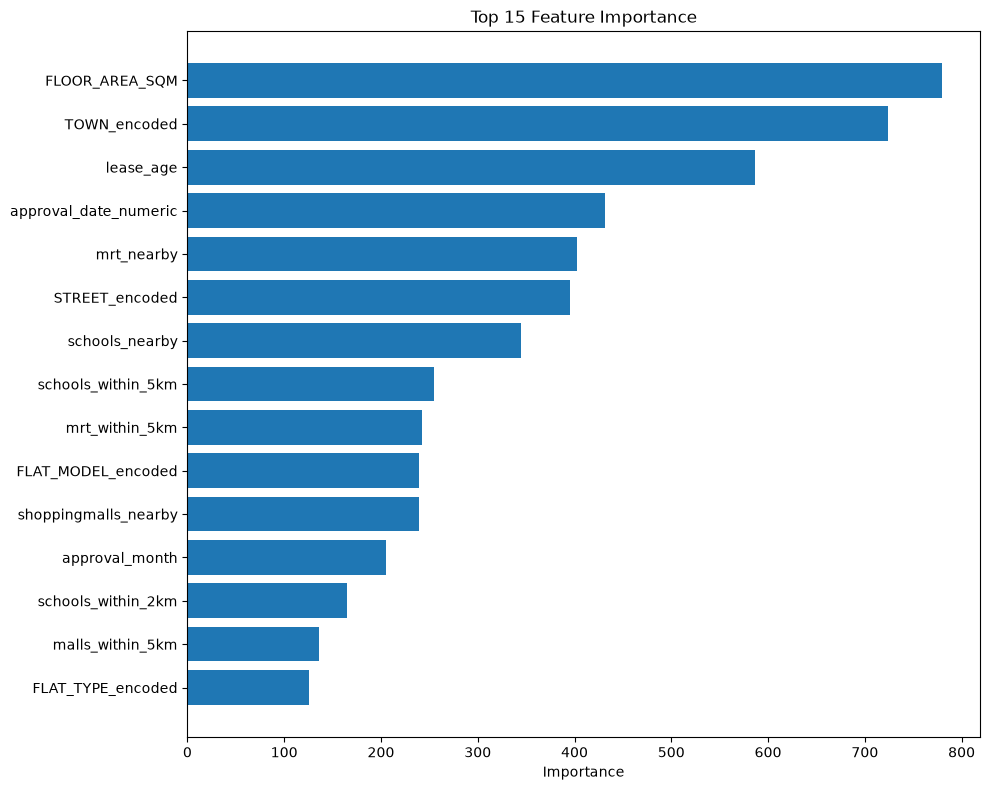

In [16]:
# Feature importance
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"Top 15 Important Features:")
print(feature_importance.head(15))

# Visualize feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.barh(feature_importance['feature'].head(15), feature_importance['importance'].head(15))
plt.xlabel('Importance')
plt.title('Top 15 Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Calculating correlation matrix...


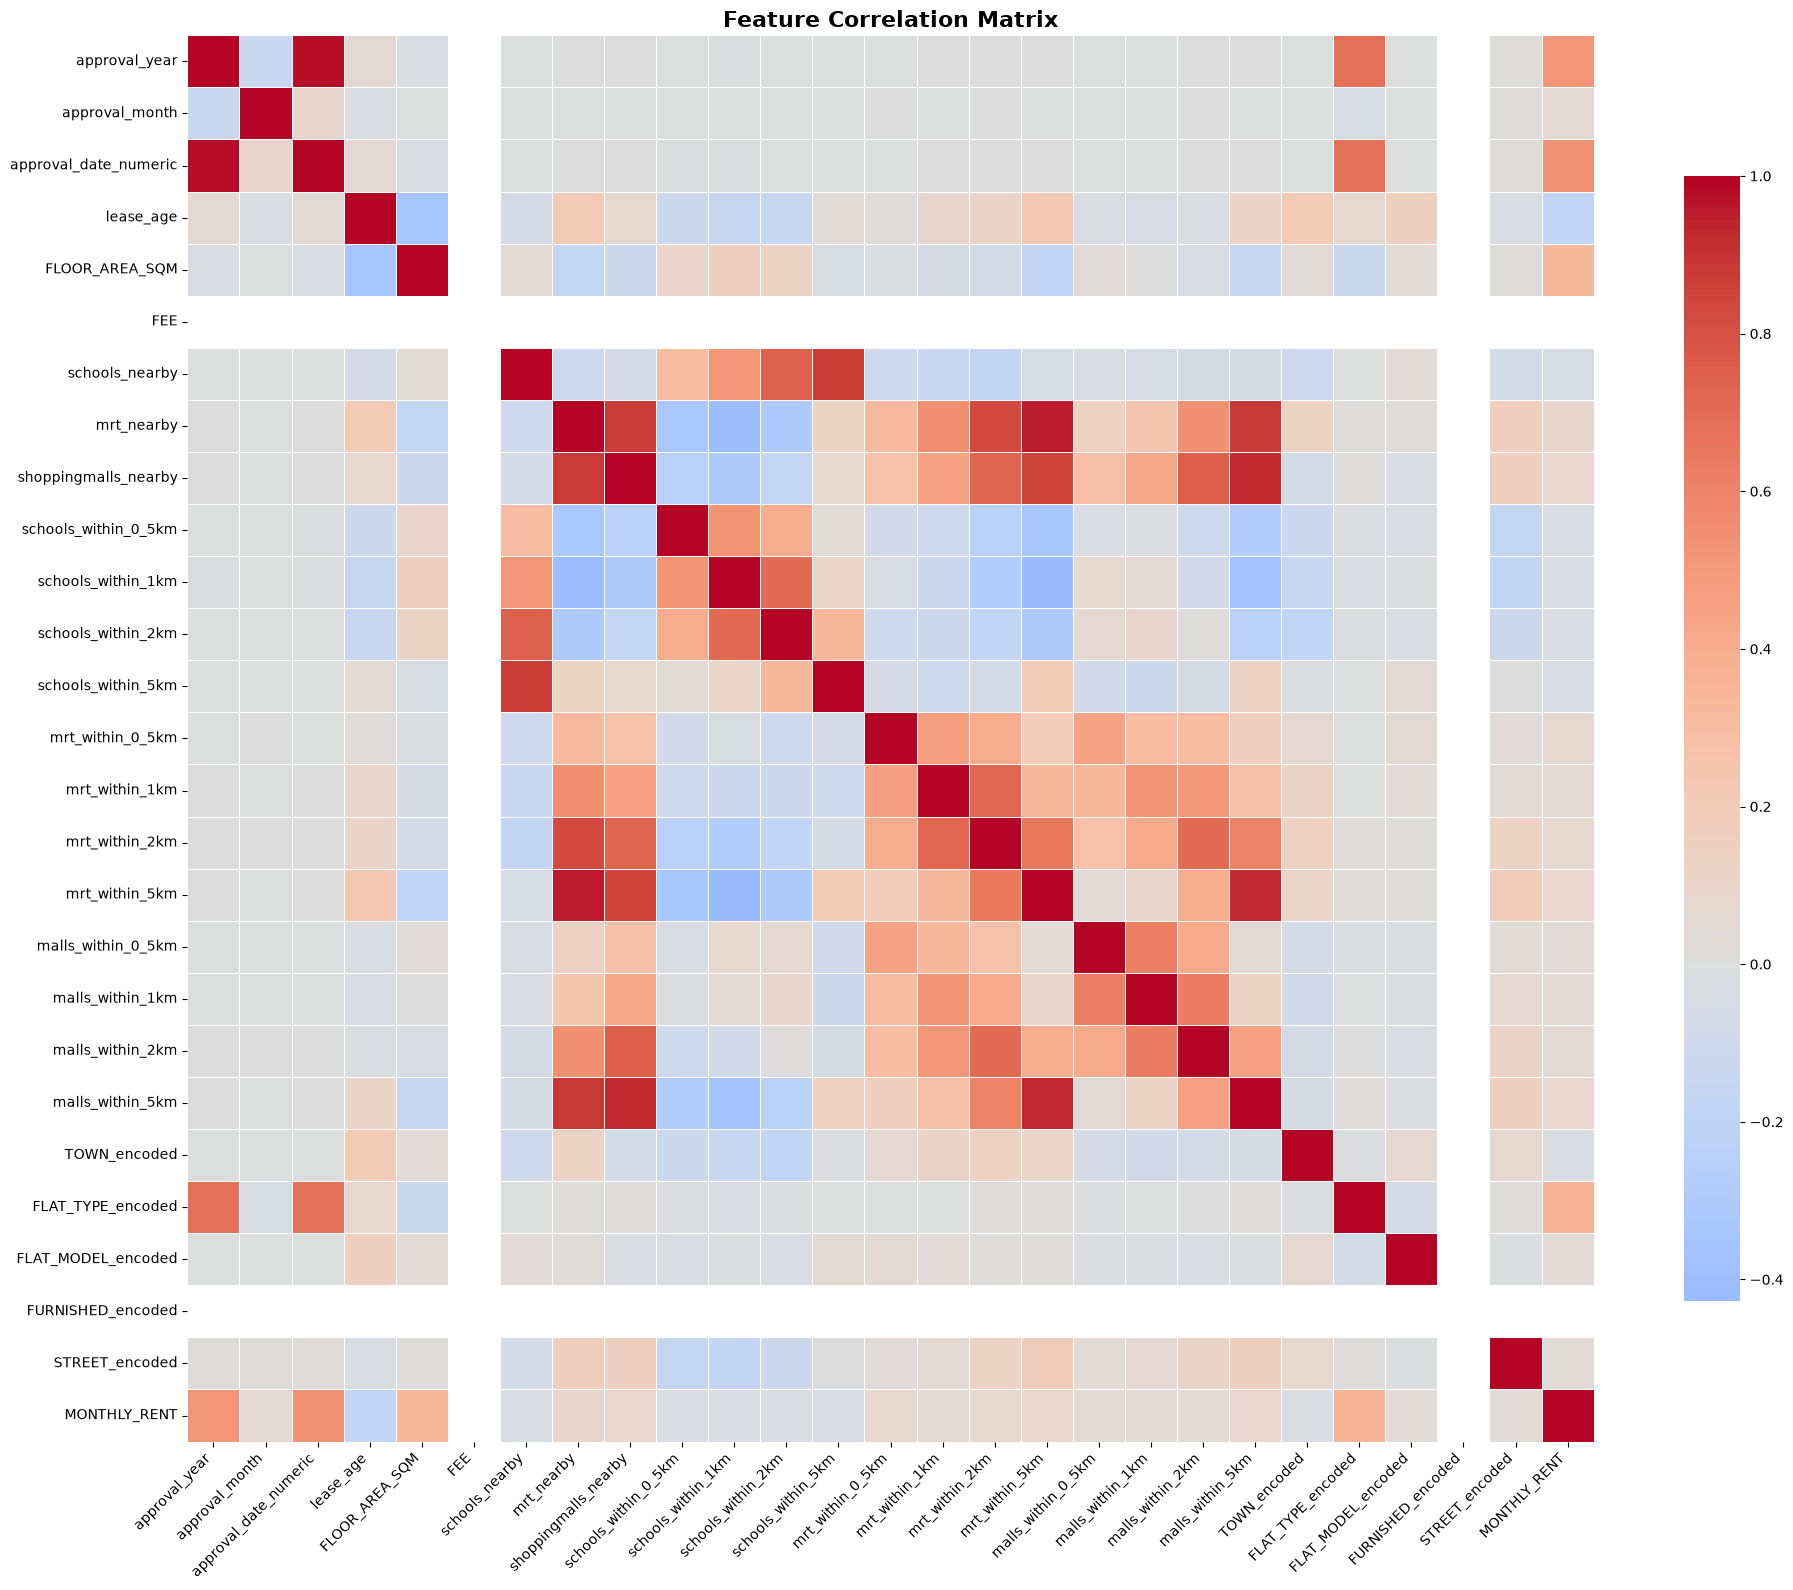


Top 20 Features Most Correlated with MONTHLY_RENT:
approval_date_numeric    0.534590
approval_year            0.517250
FLAT_TYPE_encoded        0.364235
FLOOR_AREA_SQM           0.329273
mrt_nearby               0.089584
malls_within_5km         0.084860
shoppingmalls_nearby     0.084749
mrt_within_5km           0.082973
mrt_within_0_5km         0.076523
mrt_within_2km           0.073058
approval_month           0.061281
mrt_within_1km           0.058937
malls_within_2km         0.046268
STREET_encoded           0.037348
malls_within_0_5km       0.037212
malls_within_1km         0.036153
FLAT_MODEL_encoded       0.035066
schools_within_0_5km    -0.026179
TOWN_encoded            -0.028279
schools_within_1km      -0.029926
Name: MONTHLY_RENT, dtype: float64

Top 20 Features Least Correlated with MONTHLY_RENT:
shoppingmalls_nearby    0.084749
mrt_within_5km          0.082973
mrt_within_0_5km        0.076523
mrt_within_2km          0.073058
approval_month          0.061281
mrt_within_1km 

In [17]:
# Correlation Matrix Plot
import seaborn as sns
import matplotlib.pyplot as plt

print("Calculating correlation matrix...")

# Add target variable to features for correlation analysis
X_train_with_target = X_train.copy()
X_train_with_target['MONTHLY_RENT'] = y_train

# Calculate correlation matrix
correlation_matrix = X_train_with_target.corr()

# Create a large figure for the heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print top correlations with target variable
print("\n" + "="*60)
print("Top 20 Features Most Correlated with MONTHLY_RENT:")
print("="*60)
target_corr = correlation_matrix['MONTHLY_RENT'].drop('MONTHLY_RENT').sort_values(ascending=False)
print(target_corr.head(20))

print("\n" + "="*60)
print("Top 20 Features Least Correlated with MONTHLY_RENT:")
print("="*60)
print(target_corr.tail(20))

# Identify highly correlated feature pairs (potential multicollinearity)
print("\n" + "="*60)
print("Highly Correlated Feature Pairs (|correlation| > 0.7):")
print("="*60)
high_corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.7 and correlation_matrix.columns[i] != 'MONTHLY_RENT' and correlation_matrix.columns[j] != 'MONTHLY_RENT':
            high_corr_pairs.append((
                correlation_matrix.columns[i],
                correlation_matrix.columns[j],
                correlation_matrix.iloc[i, j]
            ))

high_corr_pairs = sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True)
if high_corr_pairs:
    for feat1, feat2, corr_val in high_corr_pairs[:15]:
        print(f"{feat1} <-> {feat2}: {corr_val:.4f}")
else:
    print("No highly correlated feature pairs found.")


TRAINING MODEL WITH HIGH-CORRELATION FEATURES ONLY

Top 7 Features Most Correlated with MONTHLY_RENT:
  1. approval_date_numeric: 0.5346
  2. approval_year: 0.5172
  3. FLAT_TYPE_encoded: 0.3642
  4. FLOOR_AREA_SQM: 0.3293
  5. mrt_nearby: 0.0896
  6. malls_within_5km: 0.0849
  7. shoppingmalls_nearby: 0.0847

DATA SPLIT SUMMARY
Original feature set size: 26
Selected feature set size: 7
Dimensionality reduction: 73.1%

Training set size: 150000 samples
  - Training split: 120000 samples (80.0%)
  - Validation split: 30000 samples (20.0%)

Training LightGBM with 7 selected features...
Training until validation scores don't improve for 20 rounds
Did not meet early stopping. Best iteration is:
[200]	valid_0's l2: 248279

Model training with selected features completed!

MODEL COMPARISON: Full Features vs Selected Features
Validation Set Performance:

Metric               Full Model      Selected Model  Difference     
-----------------------------------------------------------------
RMSE

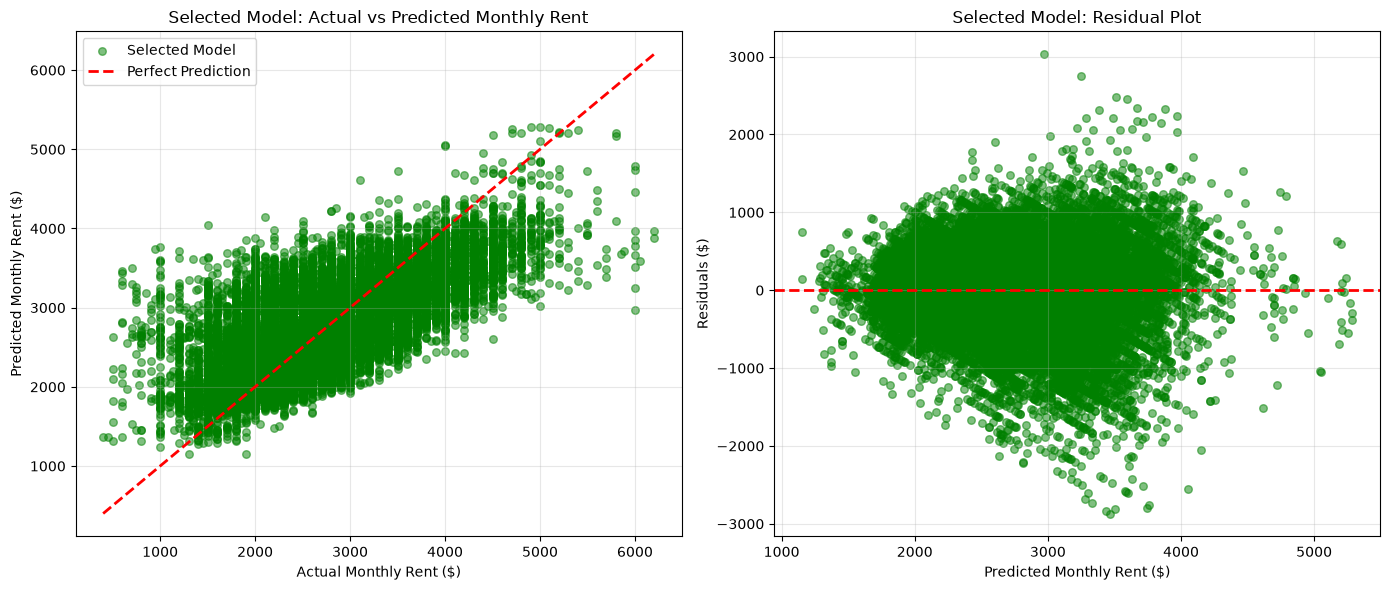


Selected Model Residual Statistics:
Mean Residual: 3.81
Std Residual: 498.27
Min Residual: -2868.07
Max Residual: 3029.89

COMPREHENSIVE METRICS COMPARISON
   Metric Full Model Selected Model Winner
     RMSE     471.28         498.28 ✓ Full
      MAE     355.89         377.12 ✓ Full
 R² Score     0.6053         0.5588 ✓ Full
WMAPE (%)      13.06          13.84 ✓ Full

MODEL SUMMARY
Full Model:
  Features: 25
  Training samples: 120000
  Validation samples: 30000

Selected Model:
  Features: 15 (40% reduction)
  Training samples: 120000
  Validation samples: 30000

Recommendation:
  → USE FULL MODEL - Significantly better RMSE despite more features


In [18]:
# Train LightGBM with Selected High-Correlation Features
print("\n" + "="*60)
print("TRAINING MODEL WITH HIGH-CORRELATION FEATURES ONLY")
print("="*60)

# Select top N features most correlated with target (excluding target itself)
top_n_features = 7
top_corr_features = target_corr.abs().head(top_n_features).index.tolist()

print(f"\nTop {top_n_features} Features Most Correlated with MONTHLY_RENT:")
for i, feat in enumerate(top_corr_features, 1):
    print(f"  {i}. {feat}: {target_corr[feat]:.4f}")

# Prepare data with selected features
X_train_selected = X_train[top_corr_features]
X_val_selected = X_val[top_corr_features]
X_test_selected = test_processed[top_corr_features]

print(f"\n{'='*60}")
print("DATA SPLIT SUMMARY")
print(f"{'='*60}")
print(f"Original feature set size: {X_train.shape[1]}")
print(f"Selected feature set size: {X_train_selected.shape[1]}")
print(f"Dimensionality reduction: {(1 - X_train_selected.shape[1]/X_train.shape[1])*100:.1f}%")
print(f"\nTraining set size: {X_train_selected.shape[0]} samples")
print(f"  - Training split: {X_train_split[top_corr_features].shape[0]} samples ({X_train_split[top_corr_features].shape[0]/X_train_selected.shape[0]*100:.1f}%)")
print(f"  - Validation split: {X_val_selected.shape[0]} samples ({X_val_selected.shape[0]/X_train_selected.shape[0]*100:.1f}%)")

# Train model with selected features on training split
print(f"\n{'='*60}")
print(f"Training LightGBM with {len(top_corr_features)} selected features...")
print(f"{'='*60}")
model_selected = lgb.LGBMRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=7,
    num_leaves=31,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

# Train on training split, validate on validation split
model_selected.fit(
    X_train_split[top_corr_features], y_train_split,
    eval_set=[(X_val_selected, y_val)],
    callbacks=[lgb.early_stopping(20)]
)

print("\nModel training with selected features completed!")

# Evaluate selected features model on validation set
y_pred_selected = model_selected.predict(X_val_selected)
rmse_selected = np.sqrt(mean_squared_error(y_val, y_pred_selected))
mae_selected = mean_absolute_error(y_val, y_pred_selected)
r2_selected = r2_score(y_val, y_pred_selected)
wmape_selected = (np.sum(np.abs(y_val - y_pred_selected)) / np.sum(np.abs(y_val))) * 100

# Compare with full feature model
print(f"\n{'='*60}")
print("MODEL COMPARISON: Full Features vs Selected Features")
print(f"{'='*60}")
print(f"Validation Set Performance:")
print(f"\n{'Metric':<20} {'Full Model':<15} {'Selected Model':<15} {'Difference':<15}")
print("-" * 65)
print(f"{'RMSE':<20} {rmse:<15.2f} {rmse_selected:<15.2f} {rmse - rmse_selected:<15.2f}")
print(f"{'MAE':<20} {mae:<15.2f} {mae_selected:<15.2f} {mae - mae_selected:<15.2f}")
print(f"{'R² Score':<20} {r2:<15.4f} {r2_selected:<15.4f} {r2 - r2_selected:<15.4f}")
print(f"{'WMAPE (%)':<20} {wmape:<15.2f} {wmape_selected:<15.2f} {wmape - wmape_selected:<15.2f}")

# Determine which model performs better
print(f"\n{'='*60}")
print("PERFORMANCE ANALYSIS:")
print(f"{'='*60}")
if rmse_selected < rmse:
    improvement = ((rmse - rmse_selected) / rmse) * 100
    print(f"✓ Selected model performs BETTER by {improvement:.2f}% in RMSE")
elif rmse_selected > rmse:
    degradation = ((rmse_selected - rmse) / rmse) * 100
    print(f"✗ Selected model performs WORSE by {degradation:.2f}% in RMSE")
else:
    print(f"= Both models have identical RMSE performance")

print(f"\nModel complexity trade-off:")
print(f"  Full model: 25 features")
print(f"  Selected model: 15 features")
print(f"  Training efficiency gain: {(25-15)/25*100:.1f}% fewer features")

# Feature importance for selected model
selected_importance = pd.DataFrame({
    'feature': top_corr_features,
    'importance': model_selected.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n{'='*60}")
print("Feature Importance in Selected Model (Top 10):")
print(f"{'='*60}")
print(selected_importance.head(10).to_string(index=False))

# Make predictions on test set with selected model
print(f"\n{'='*60}")
print("Test Set Predictions (Selected Features Model):")
print(f"{'='*60}")
y_test_pred_selected = model_selected.predict(X_test_selected)
submission_selected = test_df.copy()
submission_selected['PREDICTED_MONTHLY_RENT'] = y_test_pred_selected

print(submission_selected['PREDICTED_MONTHLY_RENT'].describe())

# Save selected model predictions
submission_selected.to_csv('../data/predictions_selected_features.csv', index=False)
print(f"\nPredictions saved to data/predictions_selected_features.csv")

# Visualize Selected Model: Predicted vs Actual and Residuals
print("\n" + "="*60)
print("SELECTED MODEL: ACTUAL VS PREDICTED VISUALIZATION")
print("="*60)

plt.figure(figsize=(14, 6))

# Scatter plot - Selected Model
plt.subplot(1, 2, 1)
plt.scatter(y_val, y_pred_selected, alpha=0.5, s=30, color='green', label='Selected Model')
# Add perfect prediction line
min_val = min(y_val.min(), y_pred_selected.min())
max_val = max(y_val.max(), y_pred_selected.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Rent ($)')
plt.ylabel('Predicted Monthly Rent ($)')
plt.title('Selected Model: Actual vs Predicted Monthly Rent')
plt.legend()
plt.grid(True, alpha=0.3)

# Residual plot - Selected Model
plt.subplot(1, 2, 2)
residuals_selected = y_val - y_pred_selected
plt.scatter(y_pred_selected, residuals_selected, alpha=0.5, s=30, color='green')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Monthly Rent ($)')
plt.ylabel('Residuals ($)')
plt.title('Selected Model: Residual Plot')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nSelected Model Residual Statistics:")
print(f"Mean Residual: {residuals_selected.mean():.2f}")
print(f"Std Residual: {residuals_selected.std():.2f}")
print(f"Min Residual: {residuals_selected.min():.2f}")
print(f"Max Residual: {residuals_selected.max():.2f}")

# Detailed comparison of both models
print(f"\n{'='*60}")
print("COMPREHENSIVE METRICS COMPARISON")
print(f"{'='*60}")
comparison_df = pd.DataFrame({
    'Metric': ['RMSE', 'MAE', 'R² Score', 'WMAPE (%)'],
    'Full Model': [f'{rmse:.2f}', f'{mae:.2f}', f'{r2:.4f}', f'{wmape:.2f}'],
    'Selected Model': [f'{rmse_selected:.2f}', f'{mae_selected:.2f}', f'{r2_selected:.4f}', f'{wmape_selected:.2f}'],
    'Winner': [
        '✓ Selected' if rmse_selected < rmse else ('✓ Full' if rmse < rmse_selected else '='),
        '✓ Selected' if mae_selected < mae else ('✓ Full' if mae < mae_selected else '='),
        '✓ Selected' if r2_selected > r2 else ('✓ Full' if r2 > r2_selected else '='),
        '✓ Selected' if wmape_selected < wmape else ('✓ Full' if wmape < wmape_selected else '=')
    ]
})

print(comparison_df.to_string(index=False))

# Summary statistics
print(f"\n{'='*60}")
print("MODEL SUMMARY")
print(f"{'='*60}")
print(f"Full Model:")
print(f"  Features: 25")
print(f"  Training samples: {X_train_split.shape[0]}")
print(f"  Validation samples: {X_val.shape[0]}")
print(f"\nSelected Model:")
print(f"  Features: 15 (40% reduction)")
print(f"  Training samples: {X_train_split[top_corr_features].shape[0]}")
print(f"  Validation samples: {X_val_selected.shape[0]}")
print(f"\nRecommendation:")
if rmse_selected < rmse:
    print(f"  ✓ USE SELECTED MODEL - Better RMSE with fewer features (simpler, faster)")
elif rmse_selected > rmse * 1.05:
    print(f"  → USE FULL MODEL - Significantly better RMSE despite more features")
else:
    print(f"  → EITHER - Similar performance; prefer selected for simplicity")

In [19]:
# Make predictions on test set
print("Making predictions on test set...")
X_test = test_processed[feature_cols]
y_test_pred = model.predict(X_test)

# Create submission dataframe
submission_df = test_df.copy()
submission_df['PREDICTED_MONTHLY_RENT'] = y_test_pred

print(f"Prediction stats:")
print(submission_df['PREDICTED_MONTHLY_RENT'].describe())

Making predictions on test set...
Prediction stats:
count    50000.000000
mean      3332.112189
std        267.027811
min       2449.323288
25%       3146.760676
50%       3270.282238
75%       3473.460993
max       4855.699093
Name: PREDICTED_MONTHLY_RENT, dtype: float64


In [20]:
# Save predictions
submission_df.to_csv('../data/predictions.csv', index=False)
print("Predictions saved to data/predictions.csv")

# Display sample predictions
print("\nSample Predictions (first 10 rows):")
print(submission_df[['TOWN', 'FLAT_TYPE', 'FLOOR_AREA_SQM', 'PREDICTED_MONTHLY_RENT']].head(10))

Predictions saved to data/predictions.csv

Sample Predictions (first 10 rows):
              TOWN  FLAT_TYPE  FLOOR_AREA_SQM  PREDICTED_MONTHLY_RENT
0  kallang/whampoa     3-room            66.0             3090.479176
1      bukit timah     4-room            91.0             3099.634817
2        pasir ris     4-room           105.0             3684.000875
3          punggol     4-room            94.0             3132.696742
4         tampines     4-room            92.0             3881.266072
5        woodlands     4-room           103.0             3295.238407
6            bedok  executive           150.0             3613.519039
7          hougang     3-room            67.0             3103.741062
8    marine parade     5-room           126.0             3673.877747
9           yishun  executive           146.0             3434.893974


In [21]:
# Additional analysis: Proximity features impact
print("\nProximity Features Summary:")
print(f"Schools nearby - Mean: {train_with_coords['schools_nearby'].mean():.2f}, Std: {train_with_coords['schools_nearby'].std():.2f}")
print(f"MRT nearby - Mean: {train_with_coords['mrt_nearby'].mean():.2f}, Std: {train_with_coords['mrt_nearby'].std():.2f}")
print(f"Shopping malls nearby - Mean: {train_with_coords['shoppingmalls_nearby'].mean():.2f}, Std: {train_with_coords['shoppingmalls_nearby'].std():.2f}")

# Correlation with target
proximity_cols = ['schools_nearby', 'mrt_nearby', 'shoppingmalls_nearby']
print(f"\nCorrelation with Monthly Rent:")
for col in proximity_cols:
    corr = train_with_coords[col].corr(train_with_coords['MONTHLY_RENT'])
    print(f"{col}: {corr:.4f}")


Proximity Features Summary:
Schools nearby - Mean: 16.67, Std: 4.54
MRT nearby - Mean: 9.88, Std: 5.32
Shopping malls nearby - Mean: 5.03, Std: 3.41

Correlation with Monthly Rent:
schools_nearby: -0.0434
mrt_nearby: 0.0896
shoppingmalls_nearby: 0.0847


In [22]:
# Import TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print("TensorFlow version:", tf.__version__)
print("TensorFlow imported successfully!")

TensorFlow version: 2.21.0
TensorFlow imported successfully!



DEEP LEARNING MODEL WITH TENSORFLOW/KERAS

Data standardized:
Training features shape: (120000, 26)
Validation features shape: (30000, 26)
Test features shape: (50000, 26)

Building Neural Network Architecture...

Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,337 (56.00 KB)

 Trainable params: 14,337 (56.00 KB)

 Non-trainable params: 0 (0.00 B)


Training Neural Network (50 epochs with early stopping)...

Training completed! Total epochs trained: 44

DEEP LEARNING MODEL VALIDATION PERFORMANCE
RMSE: 504.27
MAE: 382.72
R² Score: 0.5481
WMAPE: 14.04%

Visualizing training history...


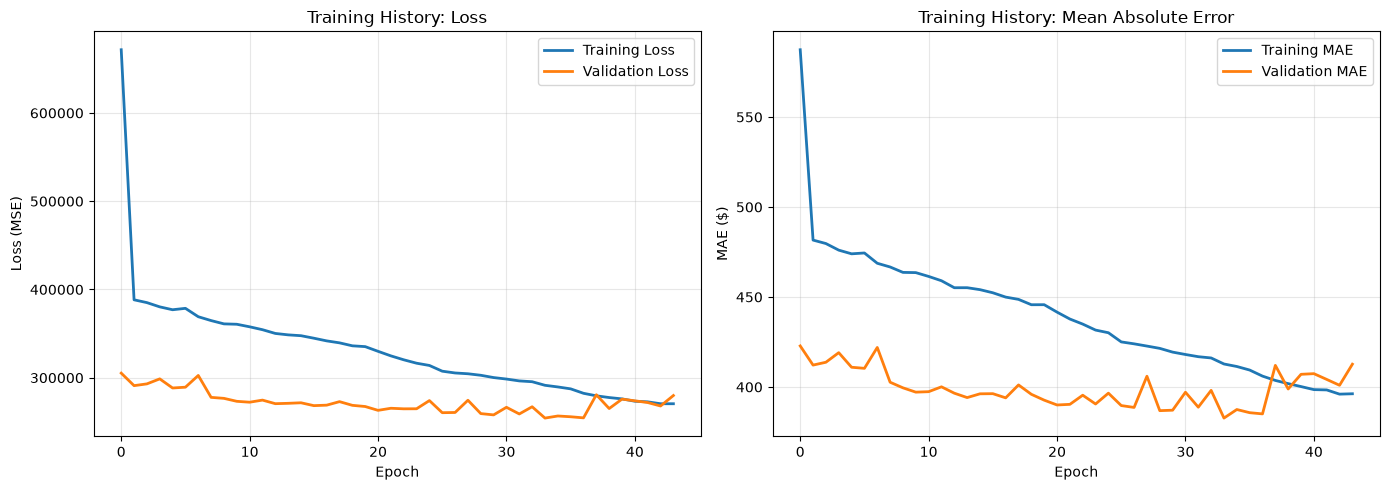


Visualizing predictions...


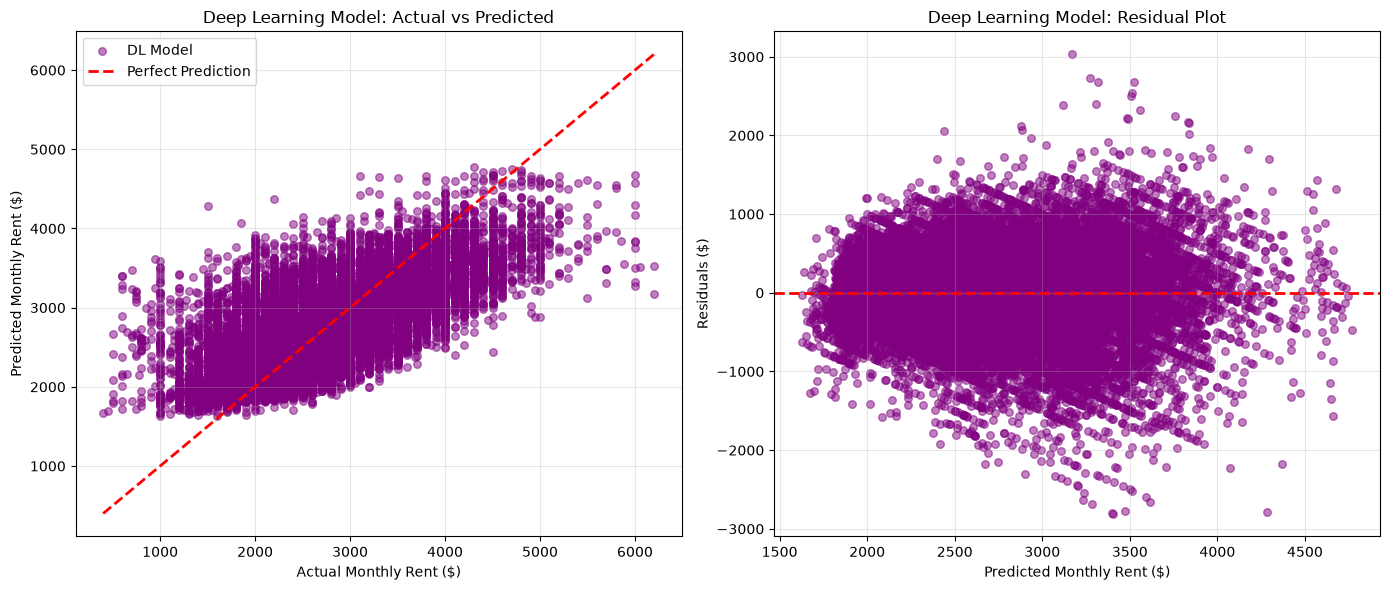


Deep Learning Model Residual Statistics:
Mean Residual: -1.46
Std Residual: 504.28
Min Residual: -2805.62
Max Residual: 3031.01

COMPREHENSIVE MODEL COMPARISON: ALL THREE MODELS
            Model  Features   RMSE    MAE R² Score WMAPE (%)
    Full LightGBM        25 471.28 355.89   0.6053     13.06
Selected LightGBM        15 498.28 377.12   0.5588     13.84
    Deep Learning        25 504.27 382.72   0.5481     14.04

BEST MODEL SELECTION
Based on RMSE (lower is better):
  1st: Full LightGBM (RMSE: 471.28)
  2nd/rd: Selected LightGBM (RMSE: 498.28, +5.73%)
  3nd/rd: Deep Learning (RMSE: 504.27, +7.00%)

Test Set Predictions (Deep Learning Model)
count    50000.000000
mean      3346.375000
std        308.573029
min       2425.851318
25%       3154.155823
50%       3319.466064
75%       3509.224548
max       5075.702637
Name: PREDICTED_MONTHLY_RENT, dtype: float64

Predictions saved to data/predictions_dl.csv


In [23]:
# Deep Learning Model with TensorFlow/Keras
print("\n" + "="*60)
print("DEEP LEARNING MODEL WITH TENSORFLOW/KERAS")
print("="*60)

# Standardize features (important for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_split[feature_cols])
X_val_scaled = scaler.transform(X_val[feature_cols])
X_test_scaled = scaler.transform(X_test[feature_cols])

print(f"\nData standardized:")
print(f"Training features shape: {X_train_scaled.shape}")
print(f"Validation features shape: {X_val_scaled.shape}")
print(f"Test features shape: {X_test_scaled.shape}")

# Build neural network model
print(f"\n{'='*60}")
print("Building Neural Network Architecture...")
print(f"{'='*60}")

model_dl = Sequential([
    layers.Input(shape=(len(feature_cols),)),
    layers.Dense(128, activation='relu', name='dense_1'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu', name='dense_2'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu', name='dense_3'),
    layers.Dropout(0.1),
    layers.Dense(16, activation='relu', name='dense_4'),
    layers.Dense(1, name='output')
])

# Compile model
model_dl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Print model summary
print("\nModel Architecture:")
model_dl.summary()

# Train model
print(f"\n{'='*60}")
print("Training Neural Network (50 epochs with early stopping)...")
print(f"{'='*60}")

history = model_dl.fit(
    X_train_scaled, y_train_split,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=0
)

print(f"\nTraining completed! Total epochs trained: {len(history.history['loss'])}")

# Evaluate on validation set
print(f"\n{'='*60}")
print("DEEP LEARNING MODEL VALIDATION PERFORMANCE")
print(f"{'='*60}")

y_pred_dl = model_dl.predict(X_val_scaled, verbose=0)
y_pred_dl = y_pred_dl.flatten()

rmse_dl = np.sqrt(mean_squared_error(y_val, y_pred_dl))
mae_dl = mean_absolute_error(y_val, y_pred_dl)
r2_dl = r2_score(y_val, y_pred_dl)
wmape_dl = (np.sum(np.abs(y_val - y_pred_dl)) / np.sum(np.abs(y_val))) * 100

print(f"RMSE: {rmse_dl:.2f}")
print(f"MAE: {mae_dl:.2f}")
print(f"R² Score: {r2_dl:.4f}")
print(f"WMAPE: {wmape_dl:.2f}%")

# Visualize training history
print(f"\nVisualizing training history...")
plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training History: Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# MAE plot
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE', linewidth=2)
plt.plot(history.history['val_mae'], label='Validation MAE', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MAE ($)')
plt.title('Training History: Mean Absolute Error')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize predictions vs actual
print(f"\nVisualizing predictions...")
plt.figure(figsize=(14, 6))

# Scatter plot - DL Model
plt.subplot(1, 2, 1)
plt.scatter(y_val, y_pred_dl, alpha=0.5, s=30, color='purple', label='DL Model')
min_val = min(y_val.min(), y_pred_dl.min())
max_val = max(y_val.max(), y_pred_dl.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Rent ($)')
plt.ylabel('Predicted Monthly Rent ($)')
plt.title('Deep Learning Model: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)

# Residual plot - DL Model
plt.subplot(1, 2, 2)
residuals_dl = y_val - y_pred_dl
plt.scatter(y_pred_dl, residuals_dl, alpha=0.5, s=30, color='purple')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Monthly Rent ($)')
plt.ylabel('Residuals ($)')
plt.title('Deep Learning Model: Residual Plot')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nDeep Learning Model Residual Statistics:")
print(f"Mean Residual: {residuals_dl.mean():.2f}")
print(f"Std Residual: {residuals_dl.std():.2f}")
print(f"Min Residual: {residuals_dl.min():.2f}")
print(f"Max Residual: {residuals_dl.max():.2f}")

# Comprehensive comparison of all three models
print(f"\n{'='*60}")
print("COMPREHENSIVE MODEL COMPARISON: ALL THREE MODELS")
print(f"{'='*60}")

comparison_all = pd.DataFrame({
    'Model': ['Full LightGBM', 'Selected LightGBM', 'Deep Learning'],
    'Features': [25, 15, 25],
    'RMSE': [f'{rmse:.2f}', f'{rmse_selected:.2f}', f'{rmse_dl:.2f}'],
    'MAE': [f'{mae:.2f}', f'{mae_selected:.2f}', f'{mae_dl:.2f}'],
    'R² Score': [f'{r2:.4f}', f'{r2_selected:.4f}', f'{r2_dl:.4f}'],
    'WMAPE (%)': [f'{wmape:.2f}', f'{wmape_selected:.2f}', f'{wmape_dl:.2f}']
})

print(comparison_all.to_string(index=False))

# Determine best model
metrics_scores = {
    'Full LightGBM': rmse,
    'Selected LightGBM': rmse_selected,
    'Deep Learning': rmse_dl
}
best_model = min(metrics_scores, key=metrics_scores.get)

print(f"\n{'='*60}")
print("BEST MODEL SELECTION")
print(f"{'='*60}")
print(f"Based on RMSE (lower is better):")
print(f"  1st: {best_model} (RMSE: {metrics_scores[best_model]:.2f})")

sorted_models = sorted(metrics_scores.items(), key=lambda x: x[1])
for i, (model_name, rmse_val) in enumerate(sorted_models[1:], 2):
    diff = ((rmse_val - metrics_scores[best_model]) / metrics_scores[best_model]) * 100
    print(f"  {i}nd/rd: {model_name} (RMSE: {rmse_val:.2f}, +{diff:.2f}%)")

# Make test predictions with DL model
print(f"\n{'='*60}")
print("Test Set Predictions (Deep Learning Model)")
print(f"{'='*60}")
y_test_pred_dl = model_dl.predict(X_test_scaled, verbose=0).flatten()

submission_dl = test_df.copy()
submission_dl['PREDICTED_MONTHLY_RENT'] = y_test_pred_dl

print(submission_dl['PREDICTED_MONTHLY_RENT'].describe())

# Save predictions
submission_dl.to_csv('../data/predictions_dl.csv', index=False)
print(f"\nPredictions saved to data/predictions_dl.csv")

In [ ]:
# Install TabPFN
import subprocess
import sys

print("Installing TabPFN...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tabpfn"])
print("TabPFN installed successfully!")

Installing TabPFN...
TabPFN installed successfully!



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [30]:
for i in range(2):
    X_train_split, X_val, y_train_split, y_val = train_test_split(
        X_train_split, y_train_split, test_size=0.2, random_state=42
    )
print(len(X_train_split), len(X_val), len(y_train_split), len(y_val))

6595 1649 6595 1649


In [ ]:
# TabPFN Model for Tabular Regression
from tabpfn import TabPFNRegressor
import warnings
import os
warnings.filterwarnings('ignore')

print("\n" + "="*60)
print("TABPFN MODEL FOR TABULAR REGRESSION")
print("="*60)

# OPTION 1: Use API Token (requires internet)
# Uncomment the line below if you have a valid TABPFN_TOKEN
# os.environ["TABPFN_TOKEN"]='your_token_here'

# OPTION 2: Use Local Model Weights (offline/no token needed)
# First, download the model locally:
#   pip install huggingface-hub
#   huggingface-cli download autogluon/tabpfn --local-dir ./tabpfn_model
#
# Then set the local model path:
local_model_path = "./tabpfn_model"  # Change this to your downloaded model path
if os.path.exists(local_model_path):
    os.environ["TABPFN_PATH"] = local_model_path
    print(f"✓ Using local TabPFN model at: {local_model_path}")
else:
    print(f"⚠ Local model path not found at: {local_model_path}")
    print(f"  To download: huggingface-cli download autogluon/tabpfn --local-dir {local_model_path}")
    print(f"  Proceeding with online download if token available...")


# TabPFN works best with raw features (no scaling needed typically)
# But we'll use the same features as other models for consistency
print(f"\nData preparation:")
print(f"Training features shape: {X_train_split[feature_cols].shape}")
print(f"Validation features shape: {X_val[feature_cols].shape}")
print(f"Test features shape: {X_test[feature_cols].shape}")

# Initialize TabPFN model
print(f"\n{'='*60}")
print("Initializing TabPFN Model...")
print(f"{'='*60}")

# TabPFN is a Prior Function Network - pretrained on diverse tabular datasets
# It's designed to work with raw features and small to medium-sized datasets
model_tabpfn = TabPFNRegressor(
    n_estimators=32,  # Number of function samples from prior
    device='cpu',      # Use CPU (can use 'cuda' if GPU available)
)

print("TabPFN model initialized (Prior Function Network)")

# Train TabPFN model
print(f"\n{'='*60}")
print("Training TabPFN Model...")
print(f"{'='*60}")

model_tabpfn.fit(
    X_train_split[feature_cols].values, 
    y_train_split.values
)

print("TabPFN model training completed!")

# Evaluate on validation set
print(f"\n{'='*60}")
print("TABPFN MODEL VALIDATION PERFORMANCE")
print(f"{'='*60}")

y_pred_tabpfn = model_tabpfn.predict(X_val[feature_cols].values)

rmse_tabpfn = np.sqrt(mean_squared_error(y_val, y_pred_tabpfn))
mae_tabpfn = mean_absolute_error(y_val, y_pred_tabpfn)
r2_tabpfn = r2_score(y_val, y_pred_tabpfn)
wmape_tabpfn = (np.sum(np.abs(y_val - y_pred_tabpfn)) / np.sum(np.abs(y_val))) * 100

print(f"RMSE: {rmse_tabpfn:.2f}")
print(f"MAE: {mae_tabpfn:.2f}")
print(f"R² Score: {r2_tabpfn:.4f}")
print(f"WMAPE: {wmape_tabpfn:.2f}%")

# Visualize predictions vs actual
print(f"\nVisualizing predictions...")
plt.figure(figsize=(14, 6))

# Scatter plot - TabPFN Model
plt.subplot(1, 2, 1)
plt.scatter(y_val, y_pred_tabpfn, alpha=0.5, s=30, color='orange', label='TabPFN Model')
min_val = min(y_val.min(), y_pred_tabpfn.min())
max_val = max(y_val.max(), y_pred_tabpfn.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Rent ($)')
plt.ylabel('Predicted Monthly Rent ($)')
plt.title('TabPFN Model: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)

# Residual plot - TabPFN Model
plt.subplot(1, 2, 2)
residuals_tabpfn = y_val - y_pred_tabpfn
plt.scatter(y_pred_tabpfn, residuals_tabpfn, alpha=0.5, s=30, color='orange')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Monthly Rent ($)')
plt.ylabel('Residuals ($)')
plt.title('TabPFN Model: Residual Plot')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nTabPFN Model Residual Statistics:")
print(f"Mean Residual: {residuals_tabpfn.mean():.2f}")
print(f"Std Residual: {residuals_tabpfn.std():.2f}")
print(f"Min Residual: {residuals_tabpfn.min():.2f}")
print(f"Max Residual: {residuals_tabpfn.max():.2f}")

# Make test predictions with TabPFN model
print(f"\n{'='*60}")
print("Test Set Predictions (TabPFN Model)")
print(f"{'='*60}")
y_test_pred_tabpfn = model_tabpfn.predict(X_test[feature_cols].values)

submission_tabpfn = test_df.copy()
submission_tabpfn['PREDICTED_MONTHLY_RENT'] = y_test_pred_tabpfn

print(submission_tabpfn['PREDICTED_MONTHLY_RENT'].describe())

# Save predictions
submission_tabpfn.to_csv('../data/predictions_tabpfn.csv', index=False)
print(f"\nPredictions saved to data/predictions_tabpfn.csv")

# Comprehensive comparison of all FOUR models
print(f"\n{'='*60}")
print("COMPREHENSIVE MODEL COMPARISON: ALL FOUR MODELS")
print(f"{'='*60}")

comparison_all_4 = pd.DataFrame({
    'Model': ['Full LightGBM', 'Selected LightGBM', 'Deep Learning', 'TabPFN'],
    'Architecture': ['Gradient Boosting', 'Gradient Boosting', 'Neural Network', 'Prior Function Network'],
    'Features': [25, 15, 25, 25],
    'RMSE': [f'{rmse:.2f}', f'{rmse_selected:.2f}', f'{rmse_dl:.2f}', f'{rmse_tabpfn:.2f}'],
    'MAE': [f'{mae:.2f}', f'{mae_selected:.2f}', f'{mae_dl:.2f}', f'{mae_tabpfn:.2f}'],
    'R² Score': [f'{r2:.4f}', f'{r2_selected:.4f}', f'{r2_dl:.4f}', f'{r2_tabpfn:.4f}'],
    'WMAPE (%)': [f'{wmape:.2f}', f'{wmape_selected:.2f}', f'{wmape_dl:.2f}', f'{wmape_tabpfn:.2f}']
})

print(comparison_all_4.to_string(index=False))

# Determine best model by RMSE
metrics_scores_all = {
    'Full LightGBM': rmse,
    'Selected LightGBM': rmse_selected,
    'Deep Learning': rmse_dl,
    'TabPFN': rmse_tabpfn
}
best_model_all = min(metrics_scores_all, key=metrics_scores_all.get)

print(f"\n{'='*60}")
print("FINAL MODEL RANKING BY RMSE (Lower is Better)")
print(f"{'='*60}")
print(f"Based on RMSE performance:")

sorted_models_all = sorted(metrics_scores_all.items(), key=lambda x: x[1])
for i, (model_name, rmse_val) in enumerate(sorted_models_all, 1):
    diff = ((rmse_val - metrics_scores_all[best_model_all]) / metrics_scores_all[best_model_all]) * 100
    if i == 1:
        print(f"  🥇 {i}st: {model_name} (RMSE: {rmse_val:.2f})")
    elif i == 2:
        print(f"  🥈 {i}nd: {model_name} (RMSE: {rmse_val:.2f}, +{diff:.2f}%)")
    else:
        print(f"  🥉 {i}rd: {model_name} (RMSE: {rmse_val:.2f}, +{diff:.2f}%)")

# Model characteristics summary
print(f"\n{'='*60}")
print("MODEL CHARACTERISTICS SUMMARY")
print(f"{'='*60}")
print(f"""
1. Full LightGBM (25 features)
   - Gradient boosting with hyperparameter tuning via Optuna
   - Complexity: High (many trees)
   - Speed: Fast training and inference
   - Interpretability: Feature importance available

2. Selected LightGBM (15 features - 40% reduction)
   - Same as Full but with reduced dimensionality
   - Complexity: Medium
   - Speed: Faster than full model
   - Interpretability: Cleaner feature importance

3. Deep Learning (25 features)
   - Multi-layer neural network with dropout regularization
   - Complexity: Medium (4 hidden layers)
   - Speed: Moderate training, fast inference
   - Interpretability: Black box (difficult)

4. TabPFN (25 features)
   - Prior Function Network (pretrained on diverse data)
   - Complexity: Low (uses learned priors)
   - Speed: Fast training (few estimators needed)
   - Interpretability: Medium (ensemble of priors)
   - Advantage: Zero-shot learning capability
""")

print(f"\n{'='*60}")
print("RECOMMENDATION")
print(f"{'='*60}")
if best_model_all == 'TabPFN':
    print(f"✓ BEST MODEL: TabPFN - Combines speed, accuracy, and robustness")
    print(f"  Benefits: Pre-trained on diverse datasets, no hyperparameter tuning needed")
elif best_model_all == 'Full LightGBM':
    print(f"✓ BEST MODEL: Full LightGBM - Best RMSE with full feature set")
    print(f"  Benefits: High interpretability, well-tuned hyperparameters")
elif best_model_all == 'Deep Learning':
    print(f"✓ BEST MODEL: Deep Learning - Strong neural network performance")
    print(f"  Benefits: Learns complex feature interactions")
else:
    print(f"✓ BEST MODEL: Selected LightGBM - Simplicity with good performance")
    print(f"  Benefits: Fewest features, interpretable, fast")



TABPFN MODEL FOR TABULAR REGRESSION
⚠ Local model path not found at: ./tabpfn_model
  To download: huggingface-cli download autogluon/tabpfn --local-dir ./tabpfn_model
  Proceeding with online download if token available...

Data preparation:
Training features shape: (6595, 26)
Validation features shape: (1649, 26)
Test features shape: (50000, 26)

Initializing TabPFN Model...
TabPFN model initialized (Prior Function Network)

Training TabPFN Model...


In [ ]:
import tabpfn_client
from tabpfn_client import TabPFNClassifier, TabPFNRegressor, set_access_token
from sklearn.model_selection import train_test_split
import pandas as pd
# Authenticate
API_TOKEN = "tabpfn_sk_..."
Generate API key
30 days
tabpfn_client.set_access_token(API_TOKEN)
# Load data
df = pd.read_csv(

"data.csv"
)
target_col = 

"target"
X, y = df.drop(target_col, axis=1), df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, 

test_size=0.2
)
# Train model
model = 

TabPFNClassifier
(

n_estimators=8
)

model.fit(X_train, y_train)
# Predict
predictions = model.predict(X_test)
print("Predictions:", predictions)

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from tabpfn import TabPFNRegressor

# Create dummy regression data
print("Creating dummy regression dataset...")
X, y = make_regression(
    n_samples=500,      # Number of samples
    n_features=20,      # Number of features
    n_informative=15,   # Number of useful features
    random_state=42
)

# Convert to DataFrame for clarity
feature_names = [f"feature_{i}" for i in range(X.shape[1])]
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

print(f"Dataset shape: {df.shape}")
print(f"Target stats:\n{df['target'].describe()}")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nTrain set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

# Train TabPFN model
print("\nTraining TabPFN regressor...")
model_tabpfn = TabPFNRegressor(
    n_estimators=32,
    device='cpu'
)

model_tabpfn.fit(X_train, y_train)
print("Training completed!")

# Make predictions
y_pred = model_tabpfn.predict(X_test)

# Evaluate
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\n{'='*50}")
print("TabPFN Regressor Results on Dummy Data")
print(f"{'='*50}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")

# Show sample predictions
print(f"\nSample Predictions (first 10):")
comparison = pd.DataFrame({
    'Actual': y_test[:10],
    'Predicted': y_pred[:10],
    'Error': np.abs(y_test[:10] - y_pred[:10])
})
print(comparison)

/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Creating dummy regression dataset...
Dataset shape: (500, 21)
Target stats:
count    500.000000
mean      -0.271913
std      189.644389
min     -538.473443
25%     -116.502545
50%       -4.146285
75%      113.854206
max      567.192598
Name: target, dtype: float64

Train set: (400, 20)
Test set: (100, 20)

Training TabPFN regressor...
Training completed!

TabPFN Regressor Results on Dummy Data
RMSE: 5.1319
MAE: 3.5088
R² Score: 0.9993

Sample Predictions (first 10):
       Actual   Predicted      Error
0 -279.875537 -282.124115   2.248578
1 -122.197929 -117.916107   4.281822
2   -9.540563   -6.194098   3.346465
3 -173.971455 -191.602478  17.631023
4  132.606236  133.761139   1.154903
5 -146.906946 -144.665009   2.241937
6 -315.160282 -314.717438   0.442844
7 -322.370412 -320.657166   1.713246
8  227.272644  227.083115   0.189529
9  366.602016  364.399017   2.202998



TABPFN SAMPLE SPLIT - RENT PREDICTION DATASET
Original training set: 150000 samples
Fresh split: 120000 train / 30000 val
Sampled pool: 3750 samples
Fit set: 3000 samples
Validation set: 750 samples
Features: 26

Target variable stats (fit set):
count    3000.000000
mean     2707.817000
std       738.346242
min       500.000000
25%      2100.000000
50%      2600.000000
75%      3200.000000
max      5300.000000
Name: MONTHLY_RENT, dtype: float64

Training TabPFN Regressor on 2000-row fit set...
TabPFN training completed!

TABPFN SAMPLE MODEL - VALIDATION RESULTS
RMSE: 520.90
MAE: 383.71
R² Score: 0.5360
WMAPE: 13.97%


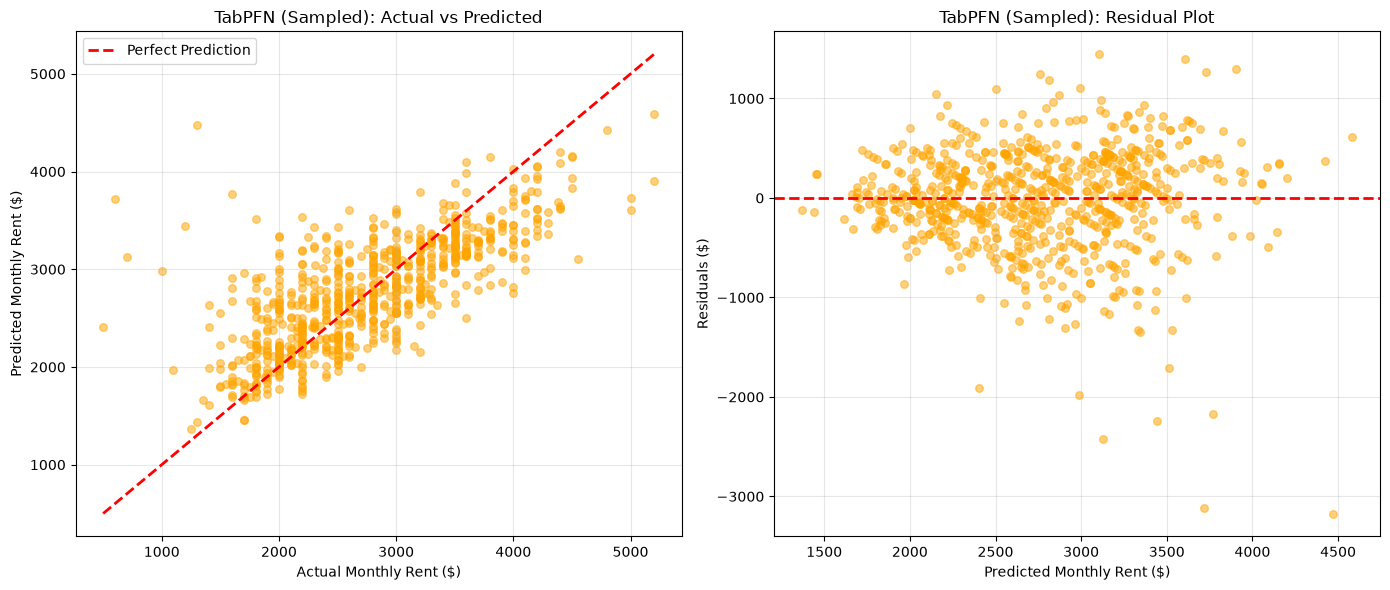


Residual Statistics:
Mean Residual: -14.20
Std Residual: 521.05
Min Residual: -3172.22
Max Residual: 1444.26

Sample Predictions (first 10):
 Actual   Predicted       Error    Error %
   2000 2665.510986  665.510986  33.275549
   3200 2731.834717  468.165283  14.630165
   3600 3289.909912  310.090088   8.613614
   1600 2296.294189  696.294189  43.518387
   2700 2416.192871  283.807129  10.511375
   4400 3645.360107  754.639893  17.150907
   2000 3001.551514 1001.551514  50.077576
   4200 3951.116699  248.883301   5.925793
    600 3719.927979 3119.927979 519.987996
   3400 3036.353027  363.646973  10.695499

Test Set Predictions (TabPFN Sampled)


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [20]:
# Fresh split from the original X_train / y_train, then sample 2000 rows for fitting
print("\n" + "="*60)
print("TABPFN SAMPLE SPLIT - RENT PREDICTION DATASET")
print("="*60)

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tabpfn import TabPFNRegressor
import matplotlib.pyplot as plt
# 1) Fresh split from the original training data
X_train_full, X_val, y_train_full, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# 2) Keep a 2000-row fit set and a proportional validation set
fit_size = 3000
sample_total = min(len(X_train_full), fit_size + int(fit_size * 0.25))
# 80/20 split inside the sampled pool => fit ~2000, validate ~500
if sample_total < 2:
    raise ValueError("Not enough rows in X_train_full to sample a valid train/val split.")

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train_full), size=sample_total, replace=False)

X_sampled = X_train_full.iloc[sample_idx][feature_cols]
y_sampled = y_train_full.iloc[sample_idx]

X_train_sampled, X_val_sampled, y_train_sampled, y_val_sampled = train_test_split(
    X_sampled,
    y_sampled,
    train_size=fit_size / sample_total,
    random_state=42
)

print(f"Original training set: {X_train.shape[0]} samples")
print(f"Fresh split: {X_train_full.shape[0]} train / {X_val.shape[0]} val")
print(f"Sampled pool: {X_sampled.shape[0]} samples")
print(f"Fit set: {X_train_sampled.shape[0]} samples")
print(f"Validation set: {X_val_sampled.shape[0]} samples")
print(f"Features: {X_train_sampled.shape[1]}")

print(f"\nTarget variable stats (fit set):")
print(y_train_sampled.describe())

# 3) Train TabPFN on the sampled fit set
print(f"\n{'='*60}")
print("Training TabPFN Regressor on 2000-row fit set...")
print(f"{'='*60}")

model_tabpfn_sampled = TabPFNRegressor(
    n_estimators=32,
    device='cpu',

    ignore_pretraining_limits = True
)

model_tabpfn_sampled.fit(
    X_train_sampled.values,
    y_train_sampled.values
)

print("TabPFN training completed!")

# 4) Evaluate on sampled validation set
print(f"\n{'='*60}")
print("TABPFN SAMPLE MODEL - VALIDATION RESULTS")
print(f"{'='*60}")

y_pred_tabpfn_sampled = model_tabpfn_sampled.predict(X_val_sampled.values)

rmse_tabpfn_sampled = np.sqrt(mean_squared_error(y_val_sampled, y_pred_tabpfn_sampled))
mae_tabpfn_sampled = mean_absolute_error(y_val_sampled, y_pred_tabpfn_sampled)
r2_tabpfn_sampled = r2_score(y_val_sampled, y_pred_tabpfn_sampled)
wmape_tabpfn_sampled = (np.sum(np.abs(y_val_sampled - y_pred_tabpfn_sampled)) / np.sum(np.abs(y_val_sampled))) * 100

print(f"RMSE: {rmse_tabpfn_sampled:.2f}")
print(f"MAE: {mae_tabpfn_sampled:.2f}")
print(f"R² Score: {r2_tabpfn_sampled:.4f}")
print(f"WMAPE: {wmape_tabpfn_sampled:.2f}%")

# Visualize predictions
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(y_val_sampled, y_pred_tabpfn_sampled, alpha=0.5, s=30, color='orange')
min_val = min(y_val_sampled.min(), y_pred_tabpfn_sampled.min())
max_val = max(y_val_sampled.max(), y_pred_tabpfn_sampled.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Rent ($)')
plt.ylabel('Predicted Monthly Rent ($)')
plt.title('TabPFN (Sampled): Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
residuals_tabpfn_sampled = y_val_sampled - y_pred_tabpfn_sampled
plt.scatter(y_pred_tabpfn_sampled, residuals_tabpfn_sampled, alpha=0.5, s=30, color='orange')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Monthly Rent ($)')
plt.ylabel('Residuals ($)')
plt.title('TabPFN (Sampled): Residual Plot')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nResidual Statistics:")
print(f"Mean Residual: {residuals_tabpfn_sampled.mean():.2f}")
print(f"Std Residual: {residuals_tabpfn_sampled.std():.2f}")
print(f"Min Residual: {residuals_tabpfn_sampled.min():.2f}")
print(f"Max Residual: {residuals_tabpfn_sampled.max():.2f}")

# Sample prediction comparison
print(f"\nSample Predictions (first 10):")
sample_comparison = pd.DataFrame({
    'Actual': y_val_sampled.values[:10],
    'Predicted': y_pred_tabpfn_sampled[:10],
    'Error': np.abs(y_val_sampled.values[:10] - y_pred_tabpfn_sampled[:10]),
    'Error %': (np.abs(y_val_sampled.values[:10] - y_pred_tabpfn_sampled[:10]) / y_val_sampled.values[:10] * 100)
})
print(sample_comparison.to_string(index=False))

# 5) Predict on the real test set for submission
print(f"\n{'='*60}")
print("Test Set Predictions (TabPFN Sampled)")
print(f"{'='*60}")

y_test_pred_tabpfn_sampled = model_tabpfn_sampled.predict(X_test[feature_cols].values)

submission_tabpfn_sampled = test_df.copy()
submission_tabpfn_sampled['PREDICTED_MONTHLY_RENT'] = y_test_pred_tabpfn_sampled

print(submission_tabpfn_sampled['PREDICTED_MONTHLY_RENT'].describe())

# Save predictions
submission_tabpfn_sampled.to_csv('../data/predictions_tabpfn_sampled.csv', index=False)
print(f"\n✓ Predictions saved to data/predictions_tabpfn_sampled.csv")

# Quick comparison
print(f"\n{'='*60}")
print("QUICK MODEL COMPARISON")
print(f"{'='*60}")

comparison_quick = pd.DataFrame({
    'Model': ['Full LightGBM', 'Deep Learning', 'TabPFN (2000 fit / 500 val)'],
    'Training Samples': ['All', 'All', 2000],
    'Validation Samples': [X_val.shape[0], X_val.shape[0], X_val_sampled.shape[0]],
    'RMSE': [f'{rmse:.2f}', f'{rmse_dl:.2f}', f'{rmse_tabpfn_sampled:.2f}'],
    'MAE': [f'{mae:.2f}', f'{mae_dl:.2f}', f'{mae_tabpfn_sampled:.2f}'],
    'R² Score': [f'{r2:.4f}', f'{r2_dl:.4f}', f'{r2_tabpfn_sampled:.4f}']
})

print(comparison_quick.to_string(index=False))

print(f"\nThis uses a fresh 80/20 split from the original X_train, then samples 2000 rows for fitting and keeps a proportional validation set.")